In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
import pandas as pd

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

### Mask definition

In [2]:
def find_box_corners(plon,plat,lon_edge,lat_edge):
    lat_min, lat_max = (plat-lat_edge/2)-20,plat+(lat_edge/2)
    lon_min, lon_max = (plon-lon_edge/2),plon+(lon_edge/2)
    if lon_max % 2.5 == 0:
        lon_max -= 0.0001
    if lat_max % 2.5 == 0:
        lat_max -= 0.0001
    return lat_min,lat_max,lon_min,lon_max

In [3]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

### Import data

In [4]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW_noRM.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_noRM.nc')

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking


In [5]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries/
dic_for_filtering_DAV = np.load('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC_tyrlis_EW_noRM.npy',allow_pickle=True) #original
dic_for_filtering_GHA = np.load('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC_noRM.npy',allow_pickle=True) #original
dics =(dic_for_filtering_DAV,dic_for_filtering_GHA)

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries


In [6]:
GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
np_array_GHA = GHA_filt.values
np_array_DAV = DAV_filt.values
np_arrays = (np_array_DAV,np_array_GHA)
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']
#ilon = list(ds_filt_DAV.lon.values).index(ds_filt_DAV.sel(lon=plon, method='nearest').lon)
#ilat = list(ds_filt_DAV.lat.values).index(ds_filt_DAV.sel(lat=plat, method='nearest').lat)
months = ['06','07','08']

# FIGURE 1 
## Trajectories

In [7]:
#create a list of labels for each IBI
#element 0 is DAV, 1 is GHA, 2 is MIX
labels = [[],[]]
timings = [[],[]]
min_pers = (5,5)
for t,time in tqdm(enumerate(times)):
    month = str(time.values)[5:7]
    if t > len(times.values)-5:
        break
    if month in months:
        for i,arr in enumerate(np_arrays):
            labels_of_the_day = np.unique(arr[t,mask_bool])
            for label in labels_of_the_day:
                check_cond = []
                for k in range(min_pers[i]):
                    #check_cond.append(np.sum(arr[t+k,mask_bool]==label)/np.sum(mask_bool) > 0.1)
                    check_cond.append(np.any(arr[t+k,mask_bool]==label))
                if label not in labels[i] and np.all(check_cond) and label!=0:
                    labels[i].append(label)
                    timings[i].append(t)
                    dics[i][label]['day_of_arrival'] = time

30677it [00:15, 1959.66it/s]


In [8]:
areas = [[],[]]
persistences = [[],[]]
intensities = [[],[]]
for j in range(2):
    for label in labels[j]:
        areas[j].append(np.mean(dics[j][label]['area']))
        persistences[j].append(dics[j][label]['persistence'])
        intensities[j].append(np.mean(np.array(dics[j][label]['intensity'])))

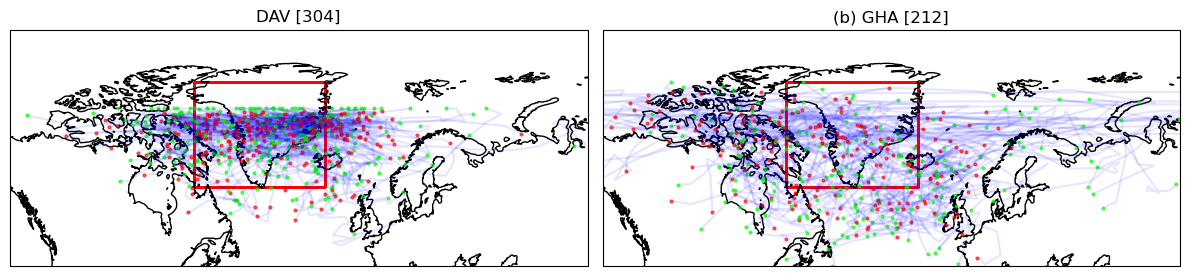

In [9]:
'''
TRAJECTORY PLOT
'''
from matplotlib.patches import Rectangle


fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), subplot_kw={'projection': ccrs.PlateCarree()})
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
titles = ['DAV [' + str(len(labels[0])) + ']','(b) GHA [' + str(len(labels[1])) + ']']
datacrs = ccrs.PlateCarree()
extent =[-140,+80,45,90]
#extent =[-180,+180,45,90]

for j in range(2):
    axarr[j].coastlines()
    axarr[j].set_aspect(2.0)
    axarr[j].set_title(titles[j])
    for l,label in enumerate(labels[j]):
        #print(label)
        #print(dics[j][label])
        cm = axarr[j].plot(dics[j][label]['track'][1],dics[j][label]['track'][0],color='blue',alpha=0.1,transform=datacrs)
        #plot the ending center of mass position
        end = axarr[j].plot(dics[j][label]['track'][1][-1],dics[j][label]['track'][0][-1],'o', markersize=2,color='r',alpha=0.6,transform=datacrs)
        #plot the starting center of mass position
        start = axarr[j].plot(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],'o', markersize=2,color='lime',alpha=0.6,transform=datacrs)
        #text = axarr[j].text(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],str(label)  )
        # Create a rectangle patch
        
        box = Rectangle(
            (lon_min, lat_min),  # Bottom-left corner
            lon_max - lon_min,   # Width (longitude difference)
            lat_max - lat_min,   # Height (latitude difference)
            linewidth=1,
            edgecolor='red',
            facecolor='none',  # Transparent fill
            transform=datacrs  # Ensure proper projection
        )
        
        # Add the box to the plot
        axarr[j].add_patch(box)
        
    axarr[j].set_extent(extent,crs=datacrs)

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure1.png')
    

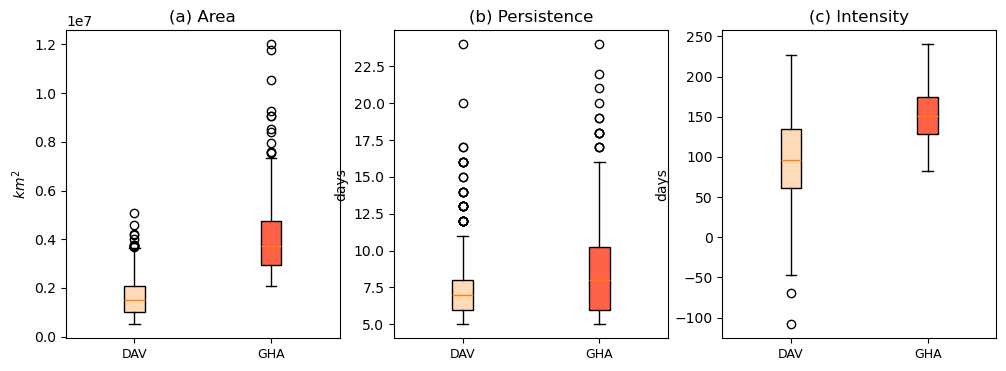

In [10]:
'''
BOXPLOT
'''

#PLOT
#it will be a multiplot devided per attribute: area, persistence and intensity
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

colors = ['peachpuff', 'tomato']
tick_labels = ['DAV','GHA']

axs[0].set_title('(a) Area')
bplot = axs[0].boxplot(areas, vert=True, patch_artist=True)
axs[0].set_xticklabels(tick_labels,fontsize=9)
axs[0].set_ylabel('$km^2$')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('(b) Persistence')
bplot = axs[1].boxplot(persistences, vert=True, patch_artist=True)
axs[1].set_xticklabels(tick_labels,fontsize=9)
axs[1].set_ylabel('days')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[2].set_title('(c) Intensity')
bplot = axs[2].boxplot(intensities, vert=True, patch_artist=True)
axs[2].set_xticklabels(tick_labels,fontsize=9)
axs[2].set_ylabel('days')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure2.png')

# FIGURE 2

## Composites

In [11]:
def deseasonalize(data_arr):
    seasonal_mean = data_arr.groupby('time.dayofyear').mean(dim='time')
    tot_mean = data_arr.mean(dim='time')
    deseasonalized_data_arr = data_arr.groupby('time.dayofyear') - seasonal_mean + tot_mean
    return deseasonalized_data_arr

In [12]:
def detrend(da, dim='time', deg=1):
    # detrend along a single dimension
    p = da.polyfit(dim=dim, deg=deg)
    fit = xr.polyval(da[dim], p.polyfit_coefficients)
    mean = da.mean(dim)
    #print(da-fit+mean)
    return da - fit + mean

In [13]:
#!ATTENTION! this deseasonalization-detrending technique only works when dataset is all-year
def rm_deseasonalize_detrend(data_arr):
    rolling_mean = data_arr.rolling(time=30, center=True, min_periods=1).mean()
    tot_mean = data_arr.mean(dim='time')
    deseasonalized_data_arr = data_arr - rolling_mean + tot_mean
    return deseasonalized_data_arr

In [14]:
#open composite datasets
ds_temp = xr.open_dataset('../../temperature/ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc')
ds_IVT = xr.open_dataset('../../IVT/ERA5_IVT_northem_daily_2.5x2.5_jja_1940-2023_mod.nc')

In [15]:
zg = ds_filt_DAV['zg']/9.81
#IVT = rm_deseasonalize_detrend(ds_IVT['IVT'])
#t2m = rm_deseasonalize_detrend(ds_temp['t2m'])
IVT = deseasonalize(ds_IVT['IVT'])
t2m = deseasonalize(ds_temp['t2m'])

In [16]:
#bootstrap function for statistical significance
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in tqdm(range(n_iter)):
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

### Lagrangian composites

In [17]:
labels_retrograding = [[],[]]
labels_upstream = [[],[]]
day_of_arrival_retrograding = [[],[]]
day_of_arrival_upstream = [[],[]]
zg_retrograding = [[],[]]
zg_upstream = [[],[]]
t2m_retrograding = [[],[]]
t2m_upstream = [[],[]]
IVT_retrograding = [[],[]]
IVT_upstream = [[],[]]
zg_mean = zg.mean('time')
IVT_mean  = IVT.mean('time')
t2m_mean = t2m.mean('time')

n_perc = 70
percentiles_h = [np.percentile(np.array(intensities[0]), n_perc),np.percentile(np.array(intensities[1]), n_perc)]
n_perc = 70
percentiles_l = [np.percentile(np.array(intensities[0]), n_perc),np.percentile(np.array(intensities[1]), n_perc)]

#populating the lists
for i,arr in enumerate(np_arrays):
    count = 0
    count_success = 0
    for j,label in tqdm(enumerate(labels[i])):
        #if sum(dics[i][label]['WBI']) > 0:
        if np.mean(np.array(dics[i][label]['intensity'])) <= percentiles_l[i]:
        #if dics[i][label]['track'][1][0] > plon:
            labels_retrograding[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if np.any(arr[t,mask_bool] == label):
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[i][label]['track'][1][dt],dics[i][label]['track'][0][dt],90,30)
                        if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                            count += 1
                        else:
                            count_success += 1
                            zg_retrograding[i].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                            t2m_retrograding[i].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            IVT_retrograding[i].append((IVT.loc[date,:,:]-IVT_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
        #if sum(dics[i][label]['WBI']) <= 0:   
        if np.mean(np.array(dics[i][label]['intensity'])) > percentiles_h[i]:
        #if dics[i][label]['track'][1][0] <= plon:
            labels_upstream[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if np.any(arr[t,mask_bool] == label):
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[i][label]['track'][1][dt],dics[i][label]['track'][0][dt],90,30)
                        if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                            count += 1
                        else:
                            count_success += 1
                            zg_upstream[i].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                            t2m_upstream[i].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            IVT_upstream[i].append((IVT.loc[date,:,:]-IVT_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
    print(count, count_success)
#computing the composites
zg_retrograding_comp = [0,0,0]
zg_retrograding_t_st = [0,0,0]
zg_upstream_comp = [0,0,0]
zg_upstream_t_st = [0,0,0]
IVT_retrograding_comp = [0,0,0]
IVT_retrograding_t_st = [0,0,0]
IVT_upstream_comp = [0,0,0]
IVT_upstream_t_st = [0,0,0]
t2m_retrograding_comp = [0,0,0]
t2m_retrograding_t_st = [0,0,0]
t2m_upstream_comp = [0,0,0]
t2m_upstream_t_st = [0,0,0]

print(len(labels_retrograding[0]),len(labels_upstream[0]),len(labels_retrograding[1]),len(labels_upstream[1]))
print(len(zg_retrograding[0]),len(zg_upstream[0]),len(zg_retrograding[1]),len(zg_upstream[1]))

304it [00:08, 36.61it/s]


0 2079


212it [00:05, 35.91it/s]

123 1406
213 91 148 64
1479 600 970 436


In [18]:
for i,var in enumerate(('DAV','GHA')):

    lat_min,lat_max,lon_min,lon_max = find_box_corners(-35,70,90,30)
    'ZG'
    zg_retrograding_comp[i] = sum(zg_retrograding[i])/len(zg_retrograding[i])
    zg_upstream_comp[i] = sum(zg_upstream[i])/len(zg_upstream[i])

    print(len(labels_retrograding[i]),len(labels_upstream[i]))
    'IVT'
    IVT_retrograding_comp[i] = sum(IVT_retrograding[i])/len(IVT_retrograding[i])# - IVT_mean
    IVT_retrograding_t_st[i] = abs(IVT_retrograding_comp[i]/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVT_retrograding[i]),100)) > 2
    IVT_upstream_comp[i] = sum(IVT_upstream[i])/len(IVT_upstream[i])# - IVT_mean
    IVT_upstream_t_st[i] = abs(IVT_upstream_comp[i]/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVT_upstream[i]),100)) > 2

    't2m'
    t2m_retrograding_comp[i] = sum(t2m_retrograding[i])/len(t2m_retrograding[i])# - t2m_mean
    t2m_retrograding_t_st[i] = abs(t2m_retrograding_comp[i]/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2m_retrograding[i]),100)) > 2
    t2m_upstream_comp[i] = sum(t2m_upstream[i])/len(t2m_upstream[i])# - t2m_mean
    t2m_upstream_t_st[i] = abs(t2m_upstream_comp[i]/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2m_upstream[i]),100)) > 2

213 91


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 228.36it/s]


148 64


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 298.69it/s]


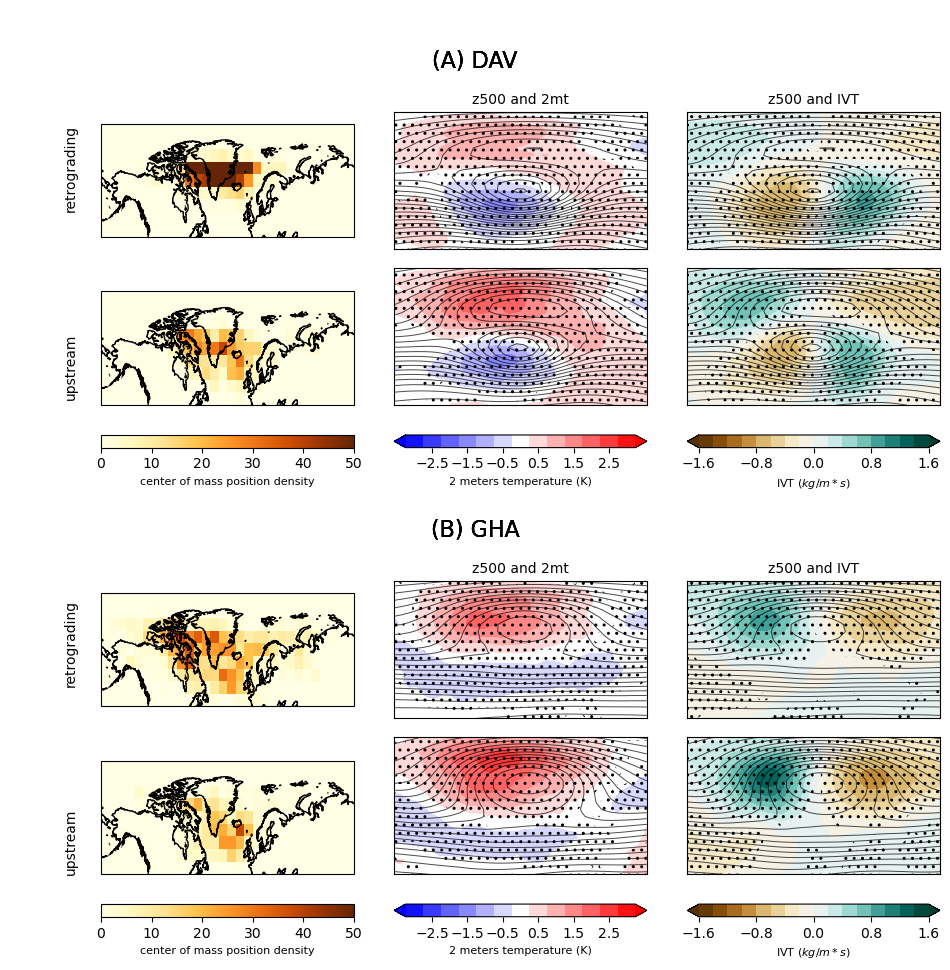

In [19]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 10
colorbar_fontsize = 8
small_titles = ['trajectories', 'z500 and 2mt', 'z500 and IVT']

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.2,1,1,1],height_ratios=[0.6,1, 1.4, 0.6, 1, 1.4], hspace=0.1)
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 20, 90]  # Greenland
density = 2
alpha_cont = 0.7
linewidths_cont = 0.7
z_levels = np.arange(4620,6000,20)
t2m_range = np.arange(-3.25,3.3,0.5)
t2m_ticks = np.arange(-2.5,2.6,1)
IVT_range = np.arange(-1.6,1.65,0.2)
IVT_ticks = np.arange(-1.6,1.7,0.8)#(-0.0225,-0.01,int(0),0.01,0.0225)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and i!=0 and i==1:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            #ax.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())
            'HISTOGRAMS 2D'
            'retrograding'
            if i == 1 and (j-1)%3==0:
                k = int((j-1)/3)
                xs = []
                ys = []
                for label in labels_retrograding[k]:
                    #xs.append(dics[k][label]['track'][1][-1])
                    #ys.append(dics[k][label]['track'][0][-1])
                    for x in dics[k][label]['track'][1]:
                        xs.append(x)
                    for y in dics[k][label]['track'][0]:
                        ys.append(y)
                hist = ax.hist2d(xs, ys, bins=(36, 18), range=[[-180, 180], [0, 90]], cmap='YlOrBr',vmin=0,vmax=50,transform=datacrs)  # Adjust bins as needed
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
            'upstream'
            if i == 1 and (j-2)%3==0:
                k = int((j-1)/3)
                xs = []
                ys = []
                for label in labels_upstream[k]:
                    #xs.append(dics[k][label]['track'][1][-1])
                    #ys.append(dics[k][label]['track'][0][-1])
                    for x in dics[k][label]['track'][1]:
                        xs.append(x)
                    for y in dics[k][label]['track'][0]:
                        ys.append(y)
                hist = ax.hist2d(xs, ys, bins=(36, 18), range=[[-180, 180], [0, 90]], cmap='YlOrBr',vmin=0,vmax=50,transform=datacrs)  # Adjust bins as needed
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
                cb = fig.colorbar(hist[3], orientation='horizontal')
                cb.set_label('center of mass position density',size=colorbar_fontsize)

        if j%3 != 0 and i!=0 and i!=1:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i])
            #ax.set_extent(extent, datacrs)
            #ax.coastlines()
            ax.set_aspect(1)#'auto')
            ax.tick_params(left = False, right = False , labelleft = False , 
                labelbottom = False, bottom = False)
            #ax.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())
            if (j-1)%3 == 0:
                ax.set_title(small_titles[i-1],fontsize=small_titles_fontsize)
            'COMPOSITES'
            't2m'
            if i == 2 and (j-1)%3==0:
                k = int((j-1)/3)
                plt.contour(zg_retrograding_comp[k],z_levels,linewidths=linewidths_cont,alpha = alpha_cont,colors='black')
                #plt.contour(zg_retrograding_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_t2m = plt.contourf(t2m_retrograding_comp[k], cmap='bwr',levels=t2m_range,extend='both')
                hatchings = ax.contourf(t2m_retrograding_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                #fig.colorbar(shad,orientation='vertical')
            if i == 2 and (j-2)%3==0:
                k = int((j-2)/3)
                plt.contour(zg_upstream_comp[k],z_levels,linewidths=linewidths_cont,alpha = alpha_cont,colors='black')
                #plt.contour(zg_upstream_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_t2m = plt.contourf(t2m_upstream_comp[k],cmap='bwr',levels=t2m_range,extend='both')
                hatchings = ax.contourf(t2m_upstream_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.']) 
                cb = fig.colorbar(shad_t2m, orientation='horizontal',ticks=t2m_ticks)
                cb.set_label('2 meters temperature (K)',size=colorbar_fontsize)

            'IVT'    
            if i == 3 and (j-1)%3==0:
                k = int((j-1)/3)
                plt.contour(zg_retrograding_comp[k],z_levels,linewidths=linewidths_cont,alpha = alpha_cont,colors='black')
                #plt.contour(zg_retrograding_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_IVT = plt.contourf(IVT_retrograding_comp[k],cmap='BrBG',levels=IVT_range,extend='both')
                hatchings = ax.contourf(IVT_retrograding_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                #fig.colorbar(shad,orientation='vertical')
            if i == 3 and (j-2)%3==0:
                k = int((j-2)/3)
                plt.contour(zg_upstream_comp[k],z_levels,linewidths=linewidths_cont,alpha = alpha_cont,colors='black')
                #plt.contour(zg_upstream_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_IVT = plt.contourf(IVT_upstream_comp[k],cmap='BrBG',levels=IVT_range,extend='both')
                hatchings = ax.contourf(IVT_upstream_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])
                cb = fig.colorbar(shad_IVT, orientation='horizontal',ticks=IVT_ticks)
                cb.set_label('IVT ($kg/m*s$)',size=colorbar_fontsize)
        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(A) DAV' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(B) GHA' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 6:
                middle_ax.text(0.5, 0.4, '(C) MIX' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure3.png')

### Temporal evolution DAV - Eulerian

In [20]:
dts = [-3,0,3]

zgs_retrograding = []
IVTs_retrograding = []
t2ms_retrograding = []

print(IVT_mean.shape)

count_exc = np.zeros(len(dts))
for i in dts:
    zgs_retrograding.append([])
    IVTs_retrograding.append([])
    t2ms_retrograding.append([])

for i,l in enumerate(labels_retrograding[0]):
    for j in range(len(dts)):
        try:
            time = dics[0][l]['day_of_arrival'] + np.timedelta64(dts[j],'D')
            zgs_retrograding[j].append(zg.loc[time,:,:])
            IVTs_retrograding[j].append(IVT.loc[time,:,:]-IVT_mean)
            t2ms_retrograding[j].append(t2m.loc[time,:,:]-t2m_mean)
        except:
            count_exc[j] -= 1

print(len(labels_retrograding[0]),count_exc)

zgs_upstream = []
IVTs_upstream = []
t2ms_upstream = []

count_exc = np.zeros(len(dts))

for i in dts:
    zgs_upstream.append([])
    IVTs_upstream.append([])
    t2ms_upstream.append([])

for i,l in enumerate(labels_upstream[0]):
    for j in range(len(dts)):
        try:
            time = dics[0][l]['day_of_arrival'] + np.timedelta64(dts[j],'D')
            zgs_upstream[j].append(zg.loc[time,:,:])
            IVTs_upstream[j].append(IVT.loc[time,:,:]-IVT_mean)
            t2ms_upstream[j].append(t2m.loc[time,:,:]-t2m_mean)
        except:
            count_exc[j] -= 1

print(len(labels_upstream[0]),count_exc)

(37, 144)
213 [-19.   0.  -3.]
91 [-10.   0.  -2.]


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 153.18it/s]


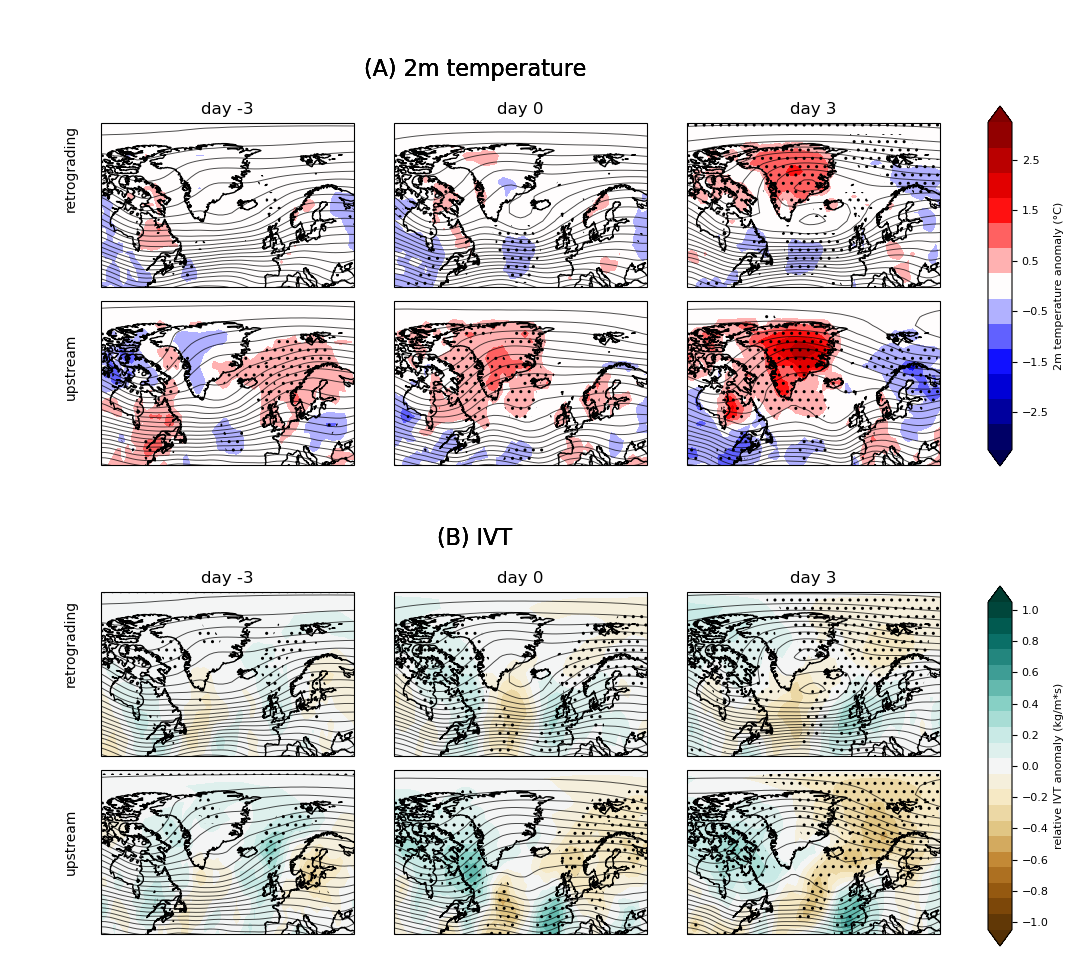

In [21]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 10
colorbar_fontsize = 8

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.2,1,1,1],height_ratios=[0.6,1, 1, 0.6, 1, 1], hspace=0.1)
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 40, 90]  # Greenland
density = 2
alpha_cont = 0.7
z_levels = np.arange(4620,6000,20)
t2m_range = np.arange(-3.25,3.3,0.5)
t2m_ticks = np.arange(-2.5,2.6,1)
IVT_range = np.arange(-1.05,1.1,0.1)
IVT_ticks = np.arange(-1.0,1.1,0.2)#(-0.0225,-0.01,int(0),0.01,0.0225)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and j < 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            '-3'
            'retrograding'
            if (j-1)%3==0:
                k = int((j-1)/3)
                t2m_comp = sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1])
                t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m,len(t2ms_retrograding[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7,transform=datacrs)
                shad_t2m = plt.contourf(lon,lat,sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1]),t2m_range,cmap='seismic',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))
                ax.set_extent(extent,datacrs)
            'upstream'
            if (j-2)%3==0:
                k = int((j-1)/3)
                t2m_comp = sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1])
                t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m,len(t2ms_upstream[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7,transform=datacrs)
                shad_t2m = plt.contourf(lon,lat,sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1]),t2m_range,cmap='seismic',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_extent(extent,datacrs)

        if j%3 != 0 and j > 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            '-3'
            'retrograding'
            if (j-1)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT,len(IVTs_upstream[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black',transform=datacrs)
                shad_IVT = plt.contourf(lon,lat,sum(IVTs_retrograding[i-1])/len(IVTs_retrograding[i-1]),IVT_range,cmap='BrBG',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))
                ax.set_extent(extent,datacrs)
            'upstream'
            if (j-2)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT,len(IVTs_upstream[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black',transform=datacrs)
                shad_IVT = plt.contourf(lon,lat,sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1]),IVT_range,cmap='BrBG',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_extent(extent,datacrs)

        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(A) 2m temperature' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(B) IVT' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

# Assuming 'fig' and 'gs' are already defined
cbar_ax_t2m = fig.add_axes([0.94, 0.50, 0.02, 0.3])  # Position for t2m colorbar
cbar_ax_IVT = fig.add_axes([0.94, 0.10, 0.02, 0.3])  # Position for IVT colorbar

# Creating the colorbars
cbar_t2m = fig.colorbar(shad_t2m,aspect=50,shrink = 0.6,cax=cbar_ax_t2m,ticks=t2m_ticks)
cbar_t2m.set_label('2m temperature anomaly (°C)', fontsize=colorbar_fontsize)
cbar_t2m.ax.tick_params(labelsize=colorbar_fontsize)

cbar_IVT = fig.colorbar(shad_IVT,aspect=50,shrink = 0.6,cax=cbar_ax_IVT,ticks=IVT_ticks)
cbar_IVT.set_label('relative IVT anomaly (kg/m*s)', fontsize=colorbar_fontsize)
cbar_IVT.ax.tick_params(labelsize=colorbar_fontsize)

### Temporal evolution GHA - Eulerian

In [22]:
dts = [-3,0,3]

zgs_retrograding = []
IVTs_retrograding = []
t2ms_retrograding = []

print(IVT_mean.shape)

count_exc = np.zeros(len(dts))
for i in dts:
    zgs_retrograding.append([])
    IVTs_retrograding.append([])
    t2ms_retrograding.append([])

for i,l in enumerate(labels_retrograding[1]):
    for j in range(len(dts)):
        try:
            time = dics[1][l]['day_of_arrival'] + np.timedelta64(dts[j],'D')
            zgs_retrograding[j].append(zg.loc[time,:,:])
            IVTs_retrograding[j].append(IVT.loc[time,:,:]-IVT_mean)
            t2ms_retrograding[j].append(t2m.loc[time,:,:]-t2m_mean)
        except:
            count_exc[j] -= 1

print(len(labels_retrograding[1]),count_exc)

zgs_upstream = []
IVTs_upstream = []
t2ms_upstream = []

count_exc = np.zeros(len(dts))

for i in dts:
    zgs_upstream.append([])
    IVTs_upstream.append([])
    t2ms_upstream.append([])

for i,l in enumerate(labels_upstream[1]):
    for j in range(len(dts)):
        try:
            time = dics[1][l]['day_of_arrival'] + np.timedelta64(dts[j],'D')
            zgs_upstream[j].append(zg.loc[time,:,:])
            IVTs_upstream[j].append(IVT.loc[time,:,:]-IVT_mean)
            t2ms_upstream[j].append(t2m.loc[time,:,:]-t2m_mean)
        except:
            count_exc[j] -= 1

print(len(labels_upstream[1]),count_exc)

(37, 144)
148 [-1.  0.  0.]
64 [-9.  0. -5.]


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 228.82it/s]


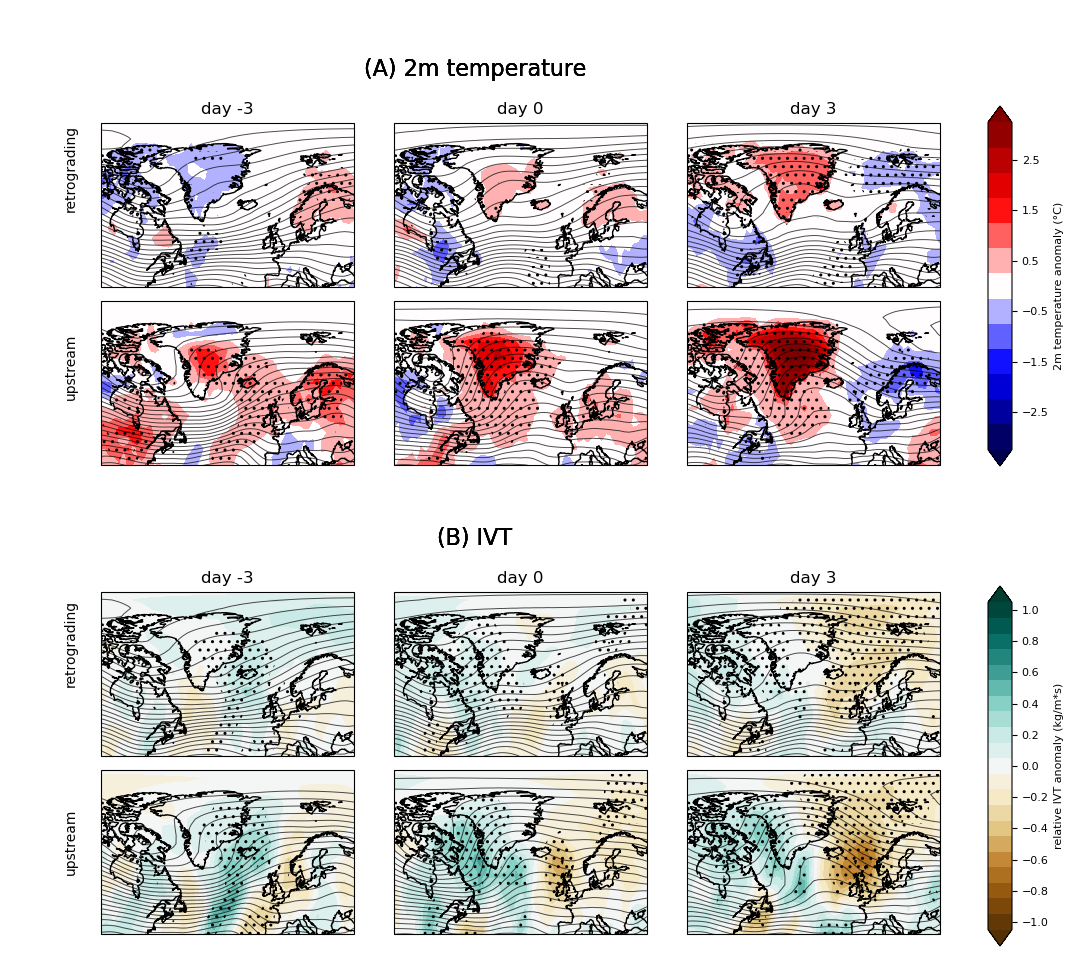

In [23]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 10
colorbar_fontsize = 8

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.2,1,1,1],height_ratios=[0.6,1, 1, 0.6, 1, 1], hspace=0.1)
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 40, 90]  # Greenland
density = 2
alpha_cont = 0.7
z_levels = np.arange(4620,6000,20)
t2m_range = np.arange(-3.25,3.3,0.5)
t2m_ticks = np.arange(-2.5,2.6,1)
IVT_range = np.arange(-1.05,1.1,0.1)
IVT_ticks = np.arange(-1.0,1.1,0.2)#(-0.0225,-0.01,int(0),0.01,0.0225)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and j < 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            '-3'
            'retrograding'
            if (j-1)%3==0:
                k = int((j-1)/3)
                t2m_comp = sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1])
                t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m,len(t2ms_retrograding[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7,transform=datacrs)
                shad_t2m = plt.contourf(lon,lat,sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1]),t2m_range,cmap='seismic',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))
                ax.set_extent(extent,datacrs)
            'upstream'
            if (j-2)%3==0:
                k = int((j-1)/3)
                t2m_comp = sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1])
                t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m,len(t2ms_upstream[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7,transform=datacrs)
                shad_t2m = plt.contourf(lon,lat,sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1]),t2m_range,cmap='seismic',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_extent(extent,datacrs)

        if j%3 != 0 and j > 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            '-3'
            'retrograding'
            if (j-1)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT,len(IVTs_upstream[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black',transform=datacrs)
                shad_IVT = plt.contourf(lon,lat,sum(IVTs_retrograding[i-1])/len(IVTs_retrograding[i-1]),IVT_range,cmap='BrBG',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))
                ax.set_extent(extent,datacrs)
            'upstream'
            if (j-2)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT,len(IVTs_upstream[i-1]),100)) > 2
                plt.contour(lon,lat,sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black',transform=datacrs)
                shad_IVT = plt.contourf(lon,lat,sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1]),IVT_range,cmap='BrBG',extend='both',transform=datacrs)
                hatchings = plt.contourf(lon,lat,IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_extent(extent,datacrs)

        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(A) 2m temperature' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(B) IVT' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

# Assuming 'fig' and 'gs' are already defined
cbar_ax_t2m = fig.add_axes([0.94, 0.50, 0.02, 0.3])  # Position for t2m colorbar
cbar_ax_IVT = fig.add_axes([0.94, 0.10, 0.02, 0.3])  # Position for IVT colorbar

# Creating the colorbars
cbar_t2m = fig.colorbar(shad_t2m,aspect=50,shrink = 0.6,cax=cbar_ax_t2m,ticks=t2m_ticks)
cbar_t2m.set_label('2m temperature anomaly (°C)', fontsize=colorbar_fontsize)
cbar_t2m.ax.tick_params(labelsize=colorbar_fontsize)

cbar_IVT = fig.colorbar(shad_IVT,aspect=50,shrink = 0.6,cax=cbar_ax_IVT,ticks=IVT_ticks)
cbar_IVT.set_label('relative IVT anomaly (kg/m*s)', fontsize=colorbar_fontsize)
cbar_IVT.ax.tick_params(labelsize=colorbar_fontsize)

# FIGURE 4

## Frequency

In [24]:
#Method 1

count_DAV = np.zeros((3))
count_GHA = np.zeros((3))
count_m = 0
freq_per_month_DAV = [[],[],[]]
freq_per_month_GHA = [[],[],[]]
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
check=0
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV_filt.values[t,mask_bool]
    GHA_gr = GHA_filt.values[t,mask_bool]
    month = str(time.values)[5:7]
    if month in months:
        #method3
        count_m += 1
        for l in np.unique(DAV_gr):
            if l in labels_retrograding[0] or l in labels_upstream[0]:
                count_DAV[0] += 1
            if l in labels_retrograding[0]:
                count_DAV[1] += 1
            if l in labels_upstream[0]:
                count_DAV[2] += 1
        for l in np.unique(GHA_gr):
            if l in labels_retrograding[1] or l in labels_upstream[1]:
                count_GHA[0] += 1
            if l in labels_retrograding[1]:
                count_GHA[1] += 1
            if l in labels_upstream[1]:
                count_GHA[2] += 1

        if month != tmp:
            check += 1
            tmp = month
            freq_per_month_DAV[0].append(count_DAV[0]*100/count_m)
            freq_per_month_GHA[0].append(count_GHA[0]*100/count_m)
            freq_per_month_DAV[1].append(count_DAV[1]*100/count_m)
            freq_per_month_GHA[1].append(count_GHA[1]*100/count_m)
            freq_per_month_DAV[2].append(count_DAV[2]*100/count_m)
            freq_per_month_GHA[2].append(count_GHA[2]*100/count_m)
            count_DAV = np.zeros((3))
            count_GHA = np.zeros((3))
            count_m = 0

print(check)

30681it [00:15, 2030.12it/s]

251


In [25]:
#Create Data Arrays

freq_per_month_DAV_DA = []
freq_per_month_GHA_DA = []

for i,f in enumerate(freq_per_month_DAV):
    # Define a time range
    date_range = pd.date_range(str(ds_filt_DAV['time'][0].values),end=str(ds_filt_DAV['time'][-1].values), freq="ME")
    # Define the months to keep
    selected_months = [6,7,8]
    # Filter the date range based on the months
    filtered_dates = date_range[date_range.month.isin(selected_months)]
    filtered_dates = filtered_dates[:-1] # correction to avoid error
    # Create the DataArray
    freq_per_month_DAV_DA.append(xr.DataArray(
    data=freq_per_month_DAV[i],  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="DAV monthly blocking frequency",  # Optional: Name of the DataArray
    attrs={"description": "DAV monthly blocking frequency over greenland"}  # Optional: Attributes
    ))

    freq_per_month_GHA_DA.append(xr.DataArray(
    data=freq_per_month_GHA[i],  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="GHA monthly blocking frequency",  # Optional: Name of the DataArray
    attrs={"description": "GHA monthly blocking frequency over greenland"}  # Optional: Attributes
    ))

In [26]:
# NORMALIZATION
date0 = '1940-06-30 06:00:00'
date1 = '1990-06-30 06:00:00'
freq_per_month_DAV_DA_normalized = []
for freq in freq_per_month_DAV_DA:
    freq_per_month_DAV_DA_normalized.append(freq/freq_per_month_DAV_DA[0].loc[date0:date1].mean())

freq_per_month_GHA_DA_normalized = []
for freq in freq_per_month_GHA_DA:
    freq_per_month_GHA_DA_normalized.append(freq/freq_per_month_GHA_DA[0].loc[date0:date1].mean())

In [27]:
def rollmean_spline_DA(DA,roll_avg_periods=3*10,s_spline=0.01):
    import scipy.interpolate as spi
    
    #Rolling mean
    rolling_mean = DA.rolling(time=roll_avg_periods, center=True).mean()
    freq = rolling_mean.values
    valid_idx = ~np.isnan(freq)
    
    #create x_ticks
    every_n_months = 30
    x_ticks = []
    locations = np.arange(0,len(freq[valid_idx]),every_n_months)
    for t,time in enumerate(DA['time'][valid_idx]):
        if t%every_n_months == 0:
            x_ticks.append(str(time.values)[:4])
    #spline
    spline = spi.UnivariateSpline(np.arange(len(freq[valid_idx])),freq[valid_idx], k=3, s=s_spline)
    xs = np.arange(len(freq[valid_idx]))
    ys = spline(np.arange(len(freq[valid_idx])))

    return ys,xs,locations,x_ticks

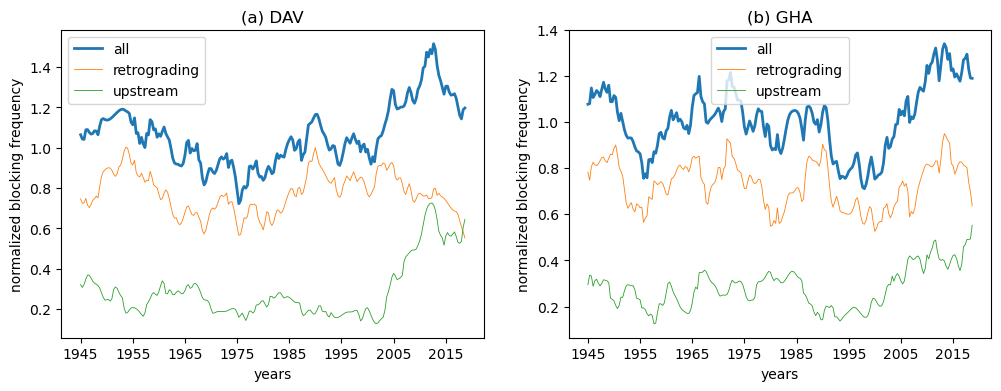

In [28]:
labels = ['all','retrograding','upstream']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].set_title('(a) DAV')
for i,DA in enumerate(freq_per_month_DAV_DA_normalized):
    ys,xs,locations,x_ticks = rollmean_spline_DA(DA)
    axes[0].plot(xs,ys,label=labels[i],linewidth=widths[i])
axes[0].legend()
axes[0].set_xticks(locations,x_ticks)
axes[0].set_xlabel('years')
axes[0].set_ylabel('normalized blocking frequency')

axes[1].set_title('(b) GHA')
for i,DA in enumerate(freq_per_month_GHA_DA_normalized):
    ys,xs,locations,x_ticks = rollmean_spline_DA(DA)
    axes[1].plot(xs,ys,label=labels[i],linewidth=widths[i])
axes[1].legend()
axes[1].set_xticks(locations,x_ticks)
axes[1].set_xlabel('years')
axes[1].set_ylabel('normalized blocking frequency')

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/lineplots.png')

INT_retrograding = [[],[]]
WBI_retrograding = [[],[]]
xs_retrograding = [[],[]]
ys_retrograding = [[],[]]

INT_upstream = [[],[]]
WBI_upstream = [[],[]]
xs_upstream = [[],[]]
ys_upstream = [[],[]]


for j,dic in enumerate(dics):
    for i,element in enumerate(dic):
        if i in labels_retrograding[j]:
            for k in range(element['persistence']):
                WBI_retrograding[j].append(sum(element['WBI'])/element['persistence'])
                INT_retrograding[j].append(sum(element['intensity'])/element['persistence'])
                xs_retrograding[j].append(element['track'][1][k])
                ys_retrograding[j].append(element['track'][0][k])
        if i in labels_upstream[j]:
            for k in range(element['persistence']):
                WBI_upstream[j].append(sum(element['WBI'])/element['persistence'])
                INT_upstream[j].append(sum(element['intensity'])/element['persistence'])
                xs_upstream[j].append(element['track'][1][k])
                ys_upstream[j].append(element['track'][0][k])

            

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_retrograding[0] # Example latitudes
lons = xs_retrograding[0]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = WBI_retrograding[0]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = -50 #Plot the scatter points with color mapping
vmax = 50
sc = ax.scatter(lons, lats, c=values, cmap='bwr', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(WBI_retrograding[0])
print(np.mean(nparr),np.std(nparr))

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_upstream[0] # Example latitudes
lons = xs_upstream[0]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = WBI_upstream[0]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = -50 #Plot the scatter points with color mapping
vmax = 50
sc = ax.scatter(lons, lats, c=values, cmap='bwr', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(WBI_upstream[0])
print(np.mean(nparr),np.std(nparr))


import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_retrograding[0] # Example latitudes
lons = xs_retrograding[0]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = INT_retrograding[0]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = 2000 #Plot the scatter points with color mapping
vmax = 4000
sc = ax.scatter(lons, lats, c=values, cmap='Reds', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(INT_retrograding[0])
print(np.mean(nparr),np.std(nparr))

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_upstream[0] # Example latitudes
lons = xs_upstream[0]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = INT_upstream[0]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = 2000 #Plot the scatter points with color mapping
vmax = 4000
sc = ax.scatter(lons, lats, c=values, cmap='Reds', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(INT_upstream[0])
print(np.mean(nparr),np.std(nparr))


import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_retrograding[1] # Example latitudes
lons = xs_retrograding[1]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = WBI_retrograding[1]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = -50 #Plot the scatter points with color mapping
vmax = 50
sc = ax.scatter(lons, lats, c=values, cmap='bwr', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(WBI_retrograding[1])
print(np.mean(nparr),np.std(nparr))

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_upstream[1] # Example latitudes
lons = xs_upstream[1]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = WBI_upstream[1]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = -50 #Plot the scatter points with color mapping
vmax = 50
sc = ax.scatter(lons, lats, c=values, cmap='bwr', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(WBI_upstream[1])
print(np.mean(nparr),np.std(nparr))


import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_retrograding[1] # Example latitudes
lons = xs_retrograding[1]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = INT_retrograding[1]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = 2000 #Plot the scatter points with color mapping
vmax = 4000
sc = ax.scatter(lons, lats, c=values, cmap='Reds', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(INT_retrograding[1])
print(np.mean(nparr),np.std(nparr))

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  ys_upstream[1] # Example latitudes
lons = xs_upstream[1]#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = INT_upstream[1]#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = 2000 #Plot the scatter points with color mapping
vmax = 4000
sc = ax.scatter(lons, lats, c=values, cmap='Reds', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()

nparr = np.array(INT_upstream[1])
print(np.mean(nparr),np.std(nparr))
